# Cassava Leaf Disease Classification

### Import all the Dependencies

In [33]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from keras import layers, Sequential, models
import pathlib
import keras
from keras.models import Sequential, load_model
from keras.layers import Dense, Activation, Conv2D, MaxPooling2D, Flatten, Dropout, BatchNormalization
from keras.optimizers import SGD
from keras import regularizers
from keras.callbacks import ModelCheckpoint

### Set all the Constants

In [17]:
BATCH_SIZE = 32
IMAGE_SIZE = 512
CHANNELS=3
EPOCHS=20

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### Import data into tensorflow dataset object

In [18]:
dataset = tf.keras.preprocessing.image_dataset_from_directory(
    "/content/drive/MyDrive/GÜNCEL_ALİBAKİ_EMRE_ORTAK_ÇALIŞMALAR/EE470_Project/Leaf_200'er_veri/train_deneme",
    seed=12,
    shuffle=True,
    image_size=(IMAGE_SIZE,IMAGE_SIZE),
    batch_size=BATCH_SIZE
)

Found 1000 files belonging to 5 classes.


In [19]:
class_names = dataset.class_names
class_names

['Cassava___bacterial_blight',
 'Cassava___brown_streak_disease',
 'Cassava___green_mottle',
 'Cassava___healthy',
 'Cassava___mosaic_disease']

### Visualize some of the images from our dataset

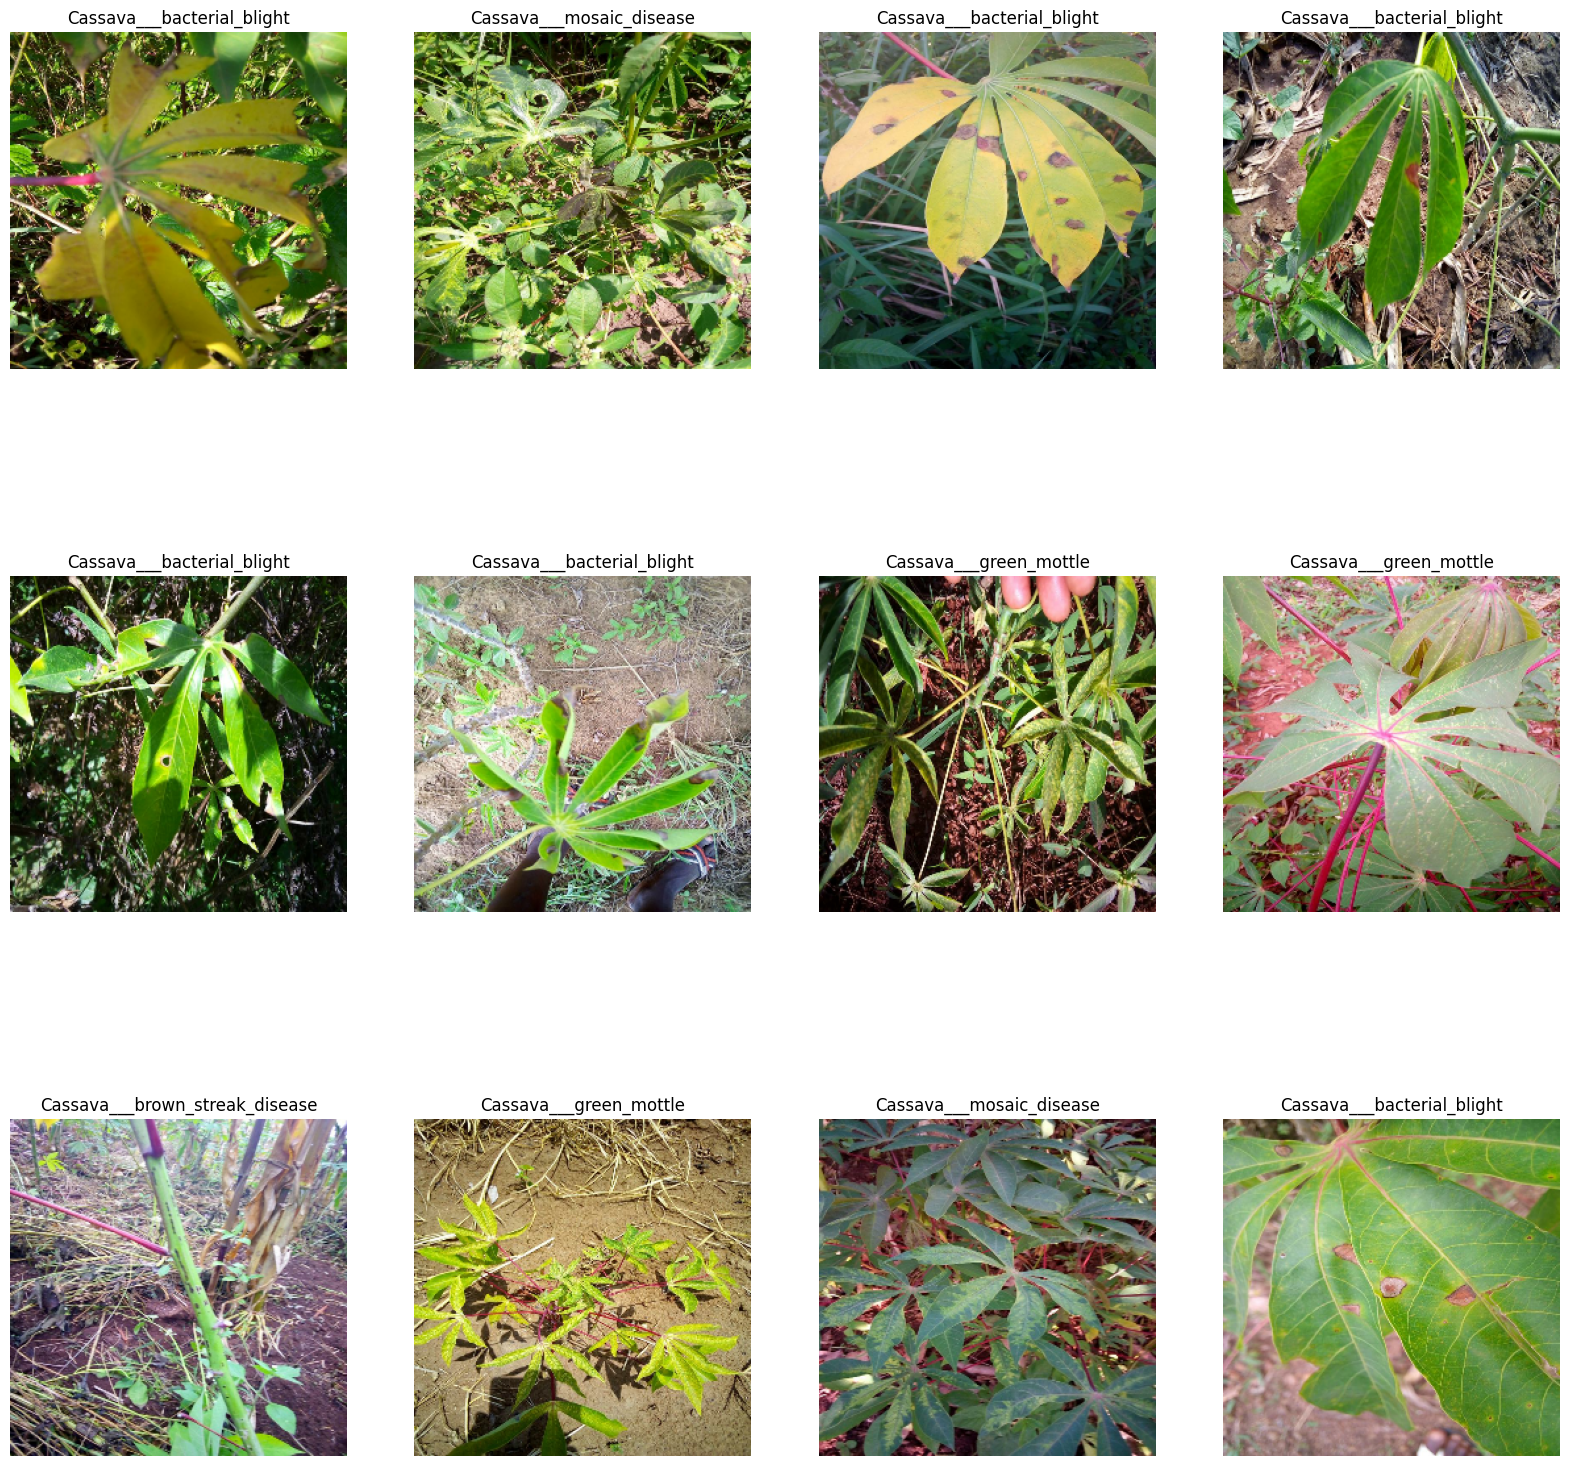

In [ ]:
plt.figure(figsize=(20, 20))
for image_batch, labels_batch in dataset.take(1):
    for i in range(12):
        ax = plt.subplot(3, 4, i + 1)
        plt.imshow(image_batch[i].numpy().astype("uint8"))
        plt.title(class_names[labels_batch[i]])
        plt.axis("off")

**Train, Test, validation data split**

In [20]:
# Dataset partitioning with checks for correct split values
def get_dataset_partitions_tf(ds, train_split=0.7, val_split=0.1, test_split=0.2, shuffle=True, shuffle_size=10000):
    # Ensure that the splits sum to 1
    total_split = train_split + val_split + test_split
    if total_split != 1:
        raise ValueError(f"Train, validation, and test splits must sum to 1. Got {total_split} instead.")

    ds_size = len(ds)  # Dataset size
    if shuffle:
        ds = ds.shuffle(buffer_size=shuffle_size, seed=42)

    train_size = int(train_split * ds_size)
    val_size = int(val_split * ds_size)

    train_ds = ds.take(train_size)
    val_ds = ds.skip(train_size).take(val_size)
    test_ds = ds.skip(train_size + val_size)

    return train_ds, val_ds, test_ds


In [21]:
train_ds, val_ds, test_ds = get_dataset_partitions_tf(dataset)

In [23]:
print("Size of Data is :{0} \nBatch size of Training Data is :{1}\nBatch size of Validation Data is :{2} \nBatch size of Testing Data is :{3} " .format(len(dataset), len(train_ds), len(val_ds), len(test_ds)))

Size of Data is :32 
Batch size of Training Data is :22
Batch size of Validation Data is :3 
Batch size of Testing Data is :7 


### Cache, Shuffle, and Prefetch the Dataset

In [22]:
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds = val_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
test_ds = test_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)

## Building the Model

### Creating a Layer for Resizing and Normalization
Before we feed our images to network, we should be resizing it to the desired size.
Moreover, to improve model performance, we should normalize the image pixel value (keeping them in range 0 and 1 by dividing by 256).
This should happen while training as well as inference. Hence we can add that as a layer in our Sequential Model.

You might be thinking why do we need to resize (256,256) image to again (256,256). You are right we don't need to but this will be useful when we are done with the training and start using the model for predictions. At that time somone can supply an image that is not (256,256) and this layer will resize it

In [24]:
resize_and_rescale = tf.keras.Sequential([
  layers.Resizing(IMAGE_SIZE, IMAGE_SIZE),
  layers.Rescaling(1./255),
])

### Data Augmentation
Data Augmentation is needed when we have less data, this boosts the accuracy of our model by augmenting the data.

In [25]:
data_augmentation = tf.keras.Sequential([
  layers.RandomFlip("horizontal_and_vertical"),
  layers.RandomRotation(0.2),
])

#### Applying Data Augmentation to Train Dataset

In [26]:
train_ds = train_ds.map(
    lambda x, y: (data_augmentation(x, training=True), y)
).prefetch(buffer_size=tf.data.AUTOTUNE)



### Model Architecture
We use a CNN coupled with a Softmax activation in the output layer. We also add the initial layers for resizing, normalization and Data Augmentation.

In [35]:
input_shape = (BATCH_SIZE, IMAGE_SIZE, IMAGE_SIZE, CHANNELS)
n_classes = 5

model = models.Sequential([
    resize_and_rescale,
    layers.Conv2D(32, kernel_size = (3,3), activation='relu', input_shape=input_shape),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64,  kernel_size = (3,3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64,  kernel_size = (3,3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(n_classes, activation='softmax'),
])

model.build(input_shape=input_shape)

In [28]:
model.summary()

Model: "sequential_5"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 sequential_3 (Sequential)   (32, 512, 512, 3)         0         
                                                                 
 conv2d_6 (Conv2D)           (32, 510, 510, 32)        896       
                                                                 
 max_pooling2d_6 (MaxPoolin  (32, 255, 255, 32)        0         
 g2D)                                                            
                                                                 
 conv2d_7 (Conv2D)           (32, 253, 253, 64)        18496     
                                                                 
 max_pooling2d_7 (MaxPoolin  (32, 126, 126, 64)        0         
 g2D)                                                            
                                                                 
 conv2d_8 (Conv2D)           (32, 124, 124, 64)       

### Compiling the Model
We use `adam` Optimizer, `SparseCategoricalCrossentropy` for losses, `accuracy` as a metric

In [29]:
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

In [30]:
history = model.fit(
    train_ds,
    batch_size=BATCH_SIZE,
    validation_data=val_ds,
    verbose=1,
    epochs=EPOCHS,
)

Epoch 1/20
22/22 [==============================] - 53s 2s/step - loss: 1.6119 - accuracy: 0.1971 - val_loss: 1.6096 - val_accuracy: 0.1667
Epoch 2/20
22/22 [==============================] - 27s 1s/step - loss: 1.6103 - accuracy: 0.2132 - val_loss: 1.6208 - val_accuracy: 0.1667
Epoch 3/20
22/22 [==============================] - 27s 1s/step - loss: 1.6103 - accuracy: 0.2132 - val_loss: 1.6128 - val_accuracy: 0.1667
Epoch 4/20
22/22 [==============================] - 28s 1s/step - loss: 1.6106 - accuracy: 0.2132 - val_loss: 1.6110 - val_accuracy: 0.1667
Epoch 5/20
22/22 [==============================] - 27s 1s/step - loss: 1.6091 - accuracy: 0.2132 - val_loss: 1.6172 - val_accuracy: 0.1667
Epoch 6/20
22/22 [==============================] - 27s 1s/step - loss: 1.6117 - accuracy: 0.2015 - val_loss: 1.6116 - val_accuracy: 0.1667
Epoch 7/20
 9/22 [===========>..................] - ETA: 16s - loss: 1.6095 - accuracy: 0.2257

KeyboardInterrupt: 

In [ ]:
scores = model.evaluate(test_ds)

4/4 [==============================] - 6s 31ms/step - loss: 1.4357 - accuracy: 0.2969


Scores is just a list containing loss and accuracy value

### Plotting the Accuracy and Loss Curves

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

Text(0.5, 1.0, 'Training and Validation Loss')

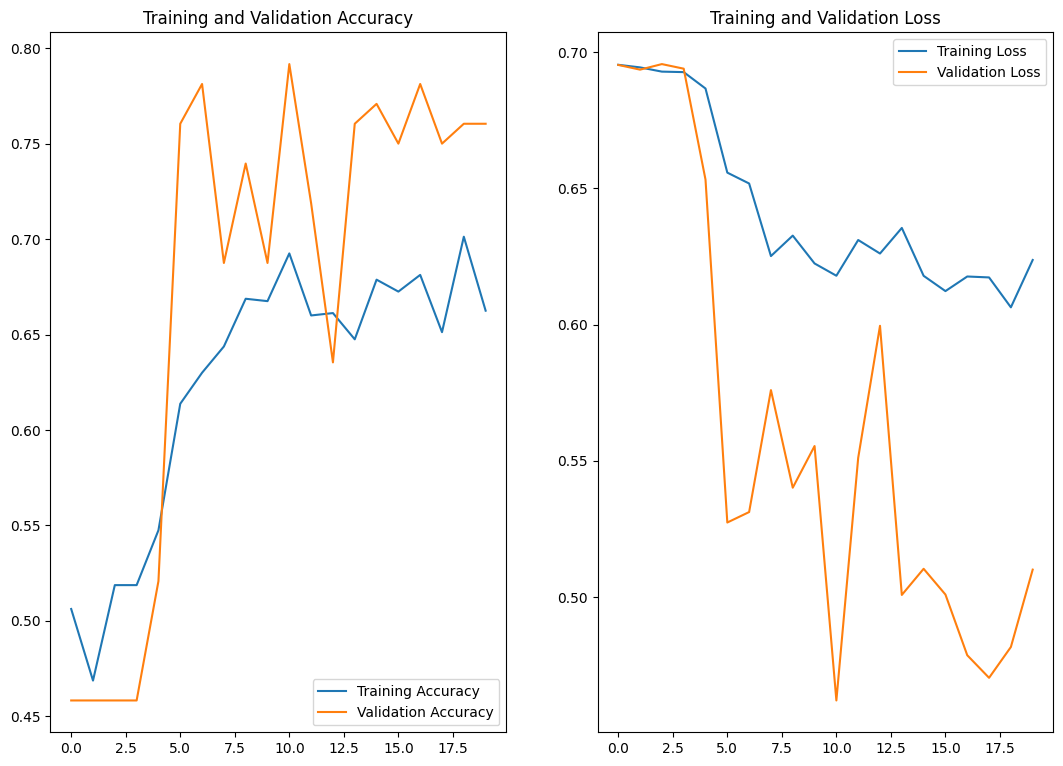

In [ ]:
#graphs for accuracy and loss of training and validation data
plt.figure(figsize = (20,20))
plt.subplot(2,3,1)
plt.plot(range(EPOCHS), acc, label = 'Training Accuracy')
plt.plot(range(EPOCHS), val_acc, label = 'Validation Accuracy')
plt.legend(loc = 'lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(2,3,2)
plt.plot(range(EPOCHS), loss, label = 'Training Loss')
plt.plot(range(EPOCHS), val_loss, label = 'Validation Loss')
plt.legend(loc = 'upper right')
plt.title('Training and Validation Loss')

### Run prediction on a sample image

first image to predict
actual label: Okrali_Grafikler_Siyah_Beyaz_512x512
1/1 [==============================] - 0s 245ms/step
predicted label: Saglikli_Grafikler_Siyah_Beyaz_512x512


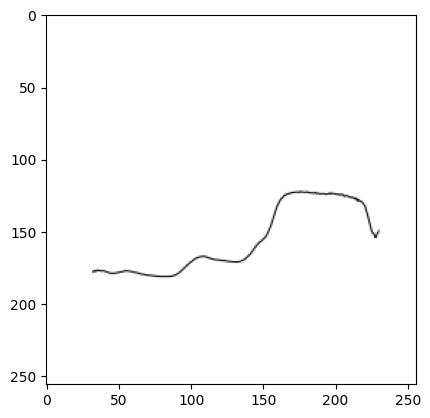

In [ ]:
import numpy as np
for images_batch, labels_batch in test_ds.take(1):

    first_image = images_batch[0].numpy().astype('uint8')
    first_label = labels_batch[0].numpy()

    print("first image to predict")
    plt.imshow(first_image)
    print("actual label:",class_names[first_label])

    batch_prediction = model.predict(images_batch)
    print("predicted label:",class_names[np.argmax(batch_prediction[0])])

### Write a function for inference

In [ ]:
def predict(model, img):
    img_array = tf.keras.preprocessing.image.img_to_array(images[i].numpy())
    img_array = tf.expand_dims(img_array, 0)

    predictions = model.predict(img_array)

    predicted_class = class_names[np.argmax(predictions[0])]
    confidence = round(100 * (np.max(predictions[0])), 2)
    return predicted_class, confidence

**Now run inference on few sample images**

1/1 [==============================] - 0s 18ms/step


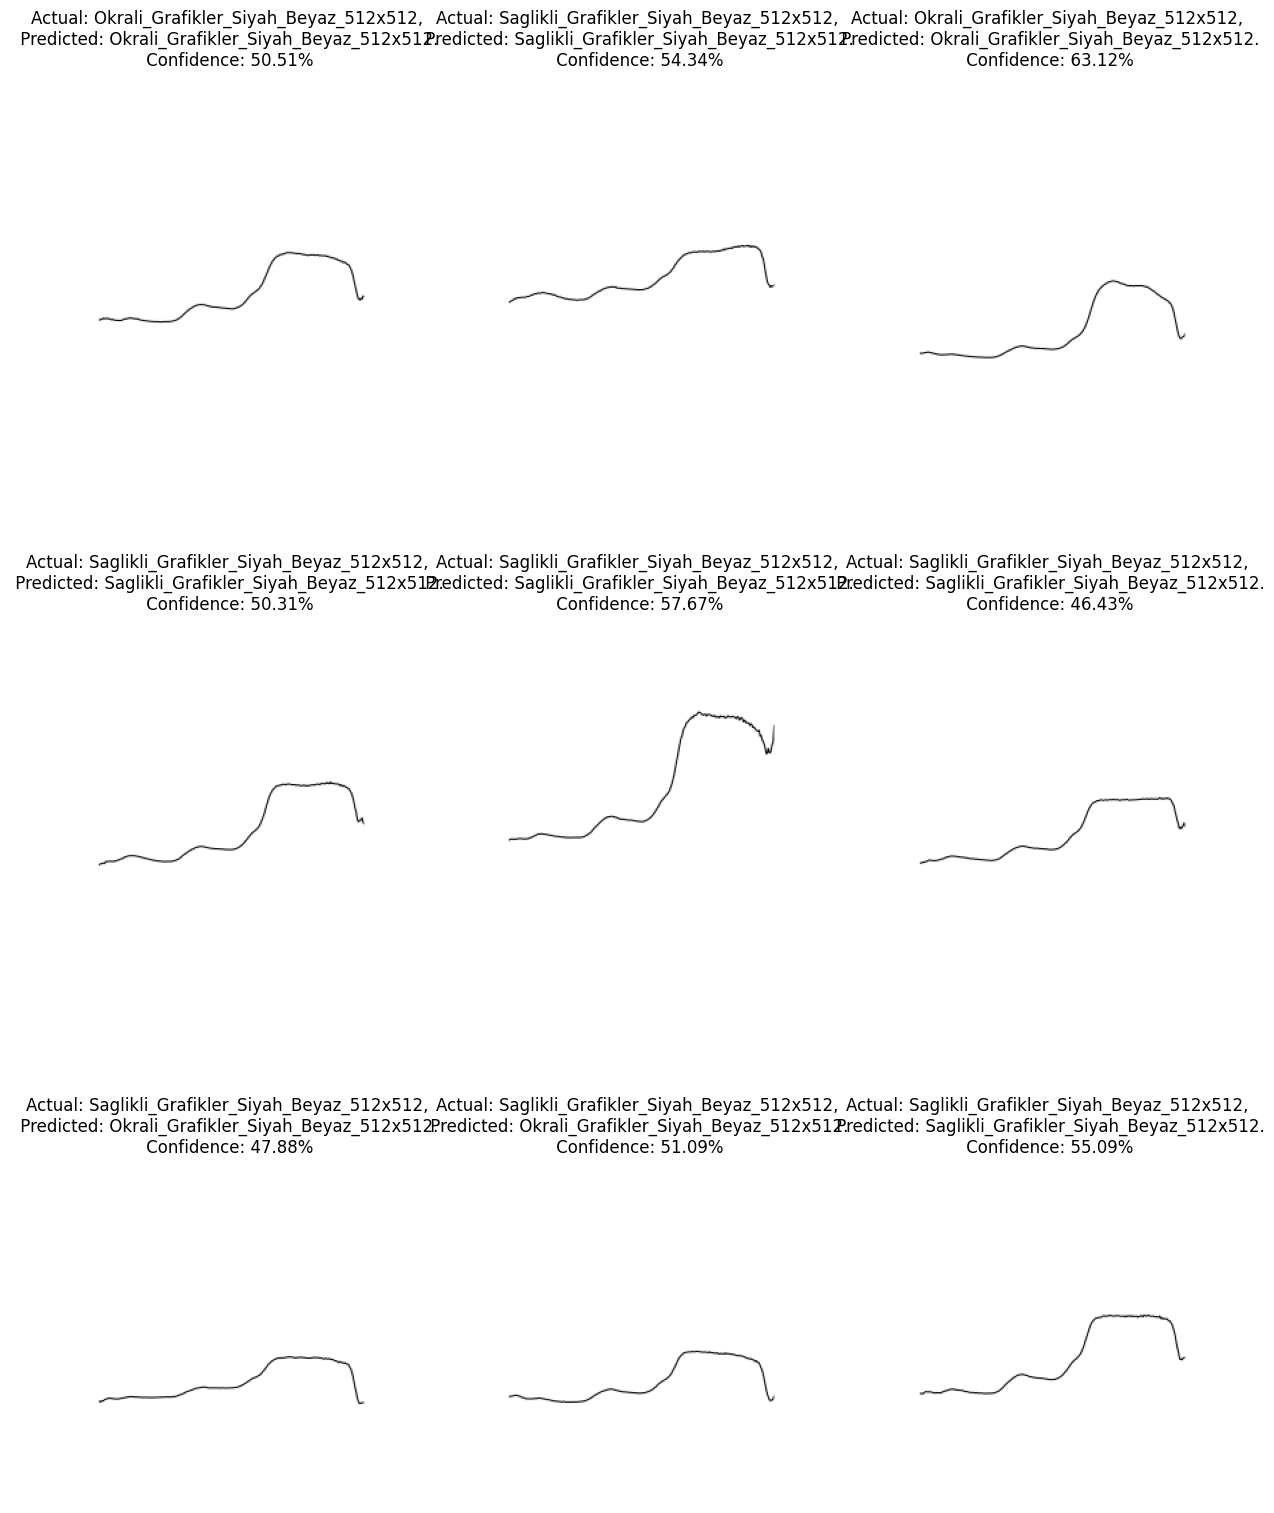

In [ ]:
plt.figure(figsize=(15, 20))
for images, labels in test_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))

        predicted_class, confidence = predict(model, images[i].numpy())
        actual_class = class_names[labels[i]]

        plt.title(f"Actual: {actual_class},\n Predicted: {predicted_class}.\n Confidence: {confidence}%")

        plt.axis("off")

# deneme


In [39]:
# Verileri Google Drive'dan yükleme
from google.colab import files
uploaded = files.upload()

# Verileri klasörlere ayırma
import os
for filename in uploaded.keys():
  path = os.path.join('data', filename)
  with open(path, 'wb') as f:
    f.write(uploaded[filename])

# Görselleri ön işleme
import cv2
import numpy as np

def preprocess_image(image_path):
  image = cv2.imread(image_path)
  image = cv2.resize(image, (224, 224)) # Modelinizin giriş boyutuna göre ayarlayın
  image = image.astype(np.float32) / 255.0
  image = np.expand_dims(image, axis=0)
  return image

# Verileri yükleme ve ön işleme
data_dir = "/content/drive/MyDrive/GÜNCEL_ALİBAKİ_EMRE_ORTAK_ÇALIŞMALAR/EE470_Project/Leaf_200'er_veri/train_deneme"
class_names = ['Cassava___mosaic_disease', 'Cassava___healthy', 'Cassava___green_mottle', 'Cassava___brown_streak_disease', 'Cassava___bacterial_blight']

train_images = []
train_labels = []

for class_name in class_names:
  class_dir = os.path.join(data_dir, class_name)
  for image_path in os.listdir(class_dir):
    image = preprocess_image(os.path.join(class_dir, image_path))
    label = class_names.index(class_name)
    train_images.append(image)
    train_labels.append(label)

train_images = np.concatenate(train_images)
train_labels = np.array(train_labels)

# Modeli oluşturma
from tensorflow.keras.applications import ResNet50V2
from tensorflow.keras.layers import Dense, Flatten, GlobalAveragePooling2D
from tensorflow.keras.models import Sequential

base_model = ResNet50V2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
for layer in base_model.layers:
  layer.trainable = False

model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Flatten(),
    Dense(5, activation='softmax')
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Modeli eğitme
history = model.fit(train_images, train_labels, epochs=10, batch_size=32, validation_split=0.2)

# Modeli kaydetme
model.save('cassava_leaf_classifier.h5')



test_images = []
test_labels = []

for class_name in class_names:
  class_dir = os.path.join('data', 'train_deneme', class_name)  # Assuming your test data is inside 'data/test' folder
  for image_path in os.listdir(class_dir):
    image = preprocess_image(os.path.join(class_dir, image_path))
    label = class_names.index(class_name)
    test_images.append(image)
    test_labels.append(label)

test_images = np.concatenate(test_images)
test_labels = np.array(test_labels)
test_loss, test_acc = model.evaluate(test_images, test_labels)
print('Test doğruluğu:', test_acc)


Epoch 1/10
25/25 [==============================] - 7s 157ms/step - loss: 1.5183 - accuracy: 0.3388 - val_loss: 9.4109 - val_accuracy: 0.0000e+00
Epoch 2/10
25/25 [==============================] - 3s 118ms/step - loss: 1.0767 - accuracy: 0.5250 - val_loss: 10.5355 - val_accuracy: 0.0000e+00
Epoch 3/10
25/25 [==============================] - 3s 123ms/step - loss: 0.9416 - accuracy: 0.6137 - val_loss: 10.8692 - val_accuracy: 0.0000e+00
Epoch 4/10
25/25 [==============================] - 3s 127ms/step - loss: 0.8642 - accuracy: 0.6625 - val_loss: 11.1299 - val_accuracy: 0.0000e+00
Epoch 5/10
25/25 [==============================] - 3s 128ms/step - loss: 0.7993 - accuracy: 0.6800 - val_loss: 11.3754 - val_accuracy: 0.0000e+00
Epoch 6/10
25/25 [==============================] - 4s 155ms/step - loss: 0.7471 - accuracy: 0.7262 - val_loss: 11.5724 - val_accuracy: 0.0000e+00
Epoch 7/10
25/25 [==============================] - 3s 138ms/step - loss: 0.7031 - accuracy: 0.7525 - val_loss: 11.9329

FileNotFoundError: [Errno 2] No such file or directory: 'data/train_deneme/Cassava___mosaic_disease'

# DENEME


ImportError: cannot import name 'np_utils' from 'keras.utils' (/usr/local/lib/python3.10/dist-packages/keras/utils/__init__.py)